<div style="background: linear-gradient(135deg, #0b3d91, #1f6feb); color: white; padding: 30px; border-radius: 12px;">
<h1 style="color:white; margin-bottom:4px;">Preprocesamiento, Feature Engineering y EDA inicial</h1>
<h3 style="color:#dbe7ff; margin-top:0;">Caso de estudio: dataset <i>Auto MPG</i></h3>
<p style="color:#dbe7ff;">Grupo 3 · 02/10/2026</p>
</div>

## Contenido

| Bloque | Temas |
|---|---|
| **Parte 1** | Qué es el preprocesamiento · Diagnóstico del dataset · Limpieza mínima · Estadística descriptiva · Gráficas exploratorias · Normalización y escalamiento (Min-Max y Standard) · Antes vs después |
| **Parte 2** | Variables numéricas vs categóricas · Codificación (mapeo manual y one-hot) · Feature engineering · Relaciones, indicadores y categorías · Visualización de variables creadas |
| **Parte 3** | Pipeline con Scikit-learn · ColumnTransformer · Imputación + escalamiento + OneHotEncoder · Resultado transformado · Documentación de variables · Conclusiones |

**Objetivo:** con Auto MPG, seleccionar variables numéricas y categóricas, imputar faltantes, escalar las numéricas, codificar una categórica, crear al menos una variable nueva y terminar con un `Pipeline` + `ColumnTransformer` mostrando el resultado transformado.


**Cómo usar este notebook:**

1. Ten a la mano el archivo `auto-mpg.csv` en tu computador. En la sección 2.2, Google Colab te pedirá que lo selecciones (botón "Elegir archivos"). En Jupyter o VS Code basta con tenerlo en la misma carpeta del notebook.
2. Ejecuta las celdas en orden con `Shift + Enter`, a medida que avanza la exposición.
3. Cada bloque de código va precedido de una explicación y seguido de una interpretación del resultado.

## Configuración del entorno

Importamos las librerías que usaremos durante toda la exposición:

- **pandas / numpy** → manipulación de datos.
- **matplotlib / seaborn** → visualización.
- **scikit-learn** → herramientas de preprocesamiento y pipelines.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Estilo visual para todas las gráficas
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)

print("Librerías cargadas correctamente ")

Librerías cargadas correctamente 


<div style="background:#0b3d91; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">PARTE 1 — Preprocesamiento, EDA y escalamiento</h1>
</div>

## 1. ¿Qué es el preprocesamiento y para qué se utiliza?

El **preprocesamiento de datos** es el conjunto de pasos que transforman los datos *crudos* (tal como llegan de una fuente) en datos *limpios y en un formato adecuado* para analizarlos o para entrenar un modelo de Machine Learning.


### Etapas típicas del flujo

```
Datos crudos → Diagnóstico → Limpieza → EDA → Transformación (escalar, codificar) → Feature Engineering → Modelo
```



## 2. Diagnóstico inicial del dataset Auto MPG

### 2.1 Contexto del dataset

**Auto MPG** es un dataset clásico del repositorio UCI Machine Learning. Contiene información de **398 automóviles** fabricados entre **1970 y 1982**. El objetivo típico es **predecir el consumo de combustible (`mpg`)** a partir de las características del vehículo.

| Variable | Descripción | Unidad |
|---|---|---|
| `mpg` | Millas por galón (**variable objetivo**) | mi/gal |
| `cylinders` | Número de cilindros del motor | — |
| `displacement` | Cilindrada (desplazamiento del motor) | pulgadas³ |
| `horsepower` | Potencia del motor | hp |
| `weight` | Peso del vehículo | libras |
| `acceleration` | Tiempo de 0 a 60 mph | segundos |
| `model year` | Año del modelo (70 = 1970) | año |
| `origin` | Región de origen: 1 = EE. UU., 2 = Europa, 3 = Japón | código |
| `car name` | Nombre del vehículo | texto |

### 2.2 Carga de datos

Al ejecutar la siguiente celda en **Google Colab** aparece un botón **"Elegir archivos"**: selecciona `auto-mpg.csv` desde tu computador y espera a que diga 100 %. Si trabajas en Jupyter o VS Code, la celda busca el CSV en la misma carpeta del notebook.

Cargamos el archivo **sin indicarle nada especial a pandas**, tal cual llega. Así podremos *descubrir* los problemas en lugar de esconderlos.

In [ ]:
# Subir el archivo desde el computador
try:
    from google.colab import files          # solo existe dentro de Google Colab
    print("Selecciona el archivo auto-mpg.csv desde tu computador:")
    subido = files.upload()
    RUTA = list(subido.keys())[0]           # nombre con el que quedó guardado
except ImportError:
    # Fuera de Colab (Jupyter, VS Code): el CSV debe estar en la misma carpeta del notebook
    RUTA = "auto-mpg.csv"

print("Archivo usado:", RUTA)
df_raw = pd.read_csv(RUTA)
print(f"Dimensiones: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas")
df_raw.head(10)

Selecciona el archivo auto-mpg.csv desde tu computador:


Saving auto-mpg.csv to auto-mpg (1).csv
Archivo usado: auto-mpg (1).csv
Dimensiones: 398 filas × 9 columnas


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.000,8,307.000,130,3504,12.000,70,1,chevrolet chevelle malibu
1,15.000,8,350.000,165,3693,11.500,70,1,buick skylark 320
2,18.000,8,318.000,150,3436,11.000,70,1,plymouth satellite
3,16.000,8,304.000,150,3433,12.000,70,1,amc rebel sst
4,17.000,8,302.000,140,3449,10.500,70,1,ford torino
5,15.000,8,429.000,198,4341,10.000,70,1,ford galaxie 500
6,14.000,8,454.000,220,4354,9.000,70,1,chevrolet impala
7,14.000,8,440.000,215,4312,8.500,70,1,plymouth fury iii
8,14.000,8,455.000,225,4425,10.000,70,1,pontiac catalina
9,15.000,8,390.000,190,3850,8.500,70,1,amc ambassador dpl


### 2.3 Estructura y tipos de dato

`info()` nos muestra cuántos valores no nulos tiene cada columna y qué tipo de dato asignó pandas.

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [ ]:
# ¿Qué valores de horsepower NO se pueden convertir a número?
no_numericos = df_raw.loc[pd.to_numeric(df_raw["horsepower"], errors="coerce").isna(), "horsepower"]
print("Valores problemáticos encontrados:", no_numericos.unique())
print("Cantidad de filas afectadas:", len(no_numericos))

Valores problemáticos encontrados: ['?']
Cantidad de filas afectadas: 6


In [ ]:
# Veamos los carros afectados
df_raw[df_raw["horsepower"] == "?"]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
32,25.000,4,98.000,?,2046,19.000,71,1,ford pinto
126,21.000,6,200.000,?,2875,17.000,74,1,ford maverick
330,40.900,4,85.000,?,1835,17.300,80,2,renault lecar deluxe
336,23.600,4,140.000,?,2905,14.300,80,1,ford mustang cobra
354,34.500,4,100.000,?,2320,15.800,81,2,renault 18i
374,23.000,4,151.000,?,3035,20.500,82,1,amc concord dl


El dataset usa el símbolo **`?`** para representar **valores faltantes**. pandas no lo reconoce como `NaN` automáticamente, así que hay que indicárselo.

### 2.4 Otros chequeos de diagnóstico

In [ ]:
print("Valores nulos (NaN) por columna:")
print(df_raw.isna().sum())
print("\nFilas duplicadas:", df_raw.duplicated().sum())
print("\nValores únicos por columna:")
print(df_raw.nunique())

Valores nulos (NaN) por columna:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

Filas duplicadas: 0

Valores únicos por columna:
mpg             129
cylinders         5
displacement     82
horsepower       94
weight          351
acceleration     95
model year       13
origin            3
car name        305
dtype: int64


## 3. Limpieza mínima previa al preprocesamiento

La **limpieza mínima** consiste en dejar el dataset en un estado coherente *antes* de transformarlo. No se trata aún de escalar ni codificar, sino de:

1. Reconocer los faltantes correctamente (`?` → `NaN`).
2. Corregir tipos de dato (`horsepower` → numérica).
3. Renombrar columnas para que sea cómodo trabajar (sin espacios).
4. Limpiar espacios sobrantes en textos.



In [ ]:
# Volvemos a cargar indicando que "?" significa valor faltante
df = pd.read_csv(RUTA, na_values="?")

# Renombrar columnas (sin espacios → más cómodo para programar)
df = df.rename(columns={"model year": "model_year", "car name": "car_name"})

# Limpiar espacios extras en el nombre del carro
df["car_name"] = df["car_name"].str.strip()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(4), int64(4), object(1)
memory usage: 28.1+ KB




### Visualizando los faltantes

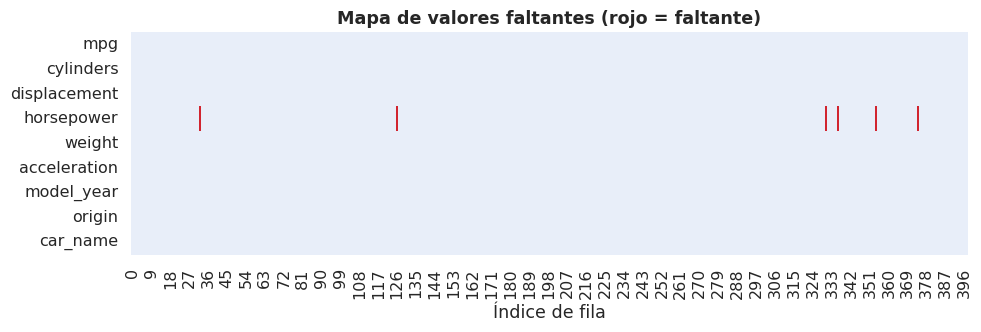

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(df.isna().T, cbar=False, cmap=["#e8eef9", "#d1242f"], ax=ax)
ax.set_title("Mapa de valores faltantes (rojo = faltante)")
ax.set_xlabel("Índice de fila")
plt.tight_layout()
plt.show()

## 4. Estadística descriptiva

La estadística descriptiva resume cada variable con pocos números:

- **Tendencia central:** media (`mean`), mediana (`50%`).
- **Dispersión:** desviación estándar (`std`), mínimo, máximo, cuartiles (`25%`, `75%`).
- **Forma:** asimetría (*skewness*). Si la media ≠ mediana, la distribución está sesgada.

In [ ]:
num_cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,398.000,23.515,7.816,9.000,17.500,23.000,29.000,46.600
cylinders,398.000,5.455,1.701,3.000,4.000,4.000,8.000,8.000
displacement,398.000,193.426,104.270,68.000,104.250,148.500,262.000,455.000
horsepower,392.000,104.469,38.491,46.000,75.000,93.500,126.000,230.000
weight,398.000,2970.425,846.842,1613.000,2223.750,2803.500,3608.000,5140.000
acceleration,398.000,15.568,2.758,8.000,13.825,15.500,17.175,24.800
model_year,398.000,76.010,3.698,70.000,73.000,76.000,79.000,82.000


In [ ]:
# Complementamos con mediana, asimetría y rango
resumen = pd.DataFrame({
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "desv_std": df[num_cols].std(),
    "rango": df[num_cols].max() - df[num_cols].min(),
    "asimetria": df[num_cols].skew(),
})
resumen

,media,mediana,desv_std,rango,asimetria
mpg,23.515,23.000,7.816,37.600,0.457
cylinders,5.455,4.000,1.701,5.000,0.527
displacement,193.426,148.500,104.270,387.000,0.720
horsepower,104.469,93.500,38.491,184.000,1.087
weight,2970.425,2803.500,846.842,3527.000,0.531
acceleration,15.568,15.500,2.758,16.800,0.279
model_year,76.010,76.000,3.698,12.000,0.012




### Estadística de las variables categóricas

In [ ]:
origen_nombres = {1: "USA", 2: "Europa", 3: "Japón"}

print("Frecuencia de origin:")
print(df["origin"].map(origen_nombres).value_counts())
print("\nFrecuencia de cylinders:")
print(df["cylinders"].value_counts().sort_index())

Frecuencia de origin:
origin
USA       249
Japón      79
Europa     70
Name: count, dtype: int64

Frecuencia de cylinders:
cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64


In [ ]:
# Media de mpg por región: primera pista de que origin importa
df.groupby(df["origin"].map(origen_nombres))[["mpg", "weight", "horsepower"]].mean().round(1)

,mpg,weight,horsepower
origin,,,
Europa,27.900,2423.300,80.600
Japón,30.500,2221.200,79.800
USA,20.100,3361.900,119.000


## 5. Primeras gráficas exploratorias




### 5.1 Histogramas

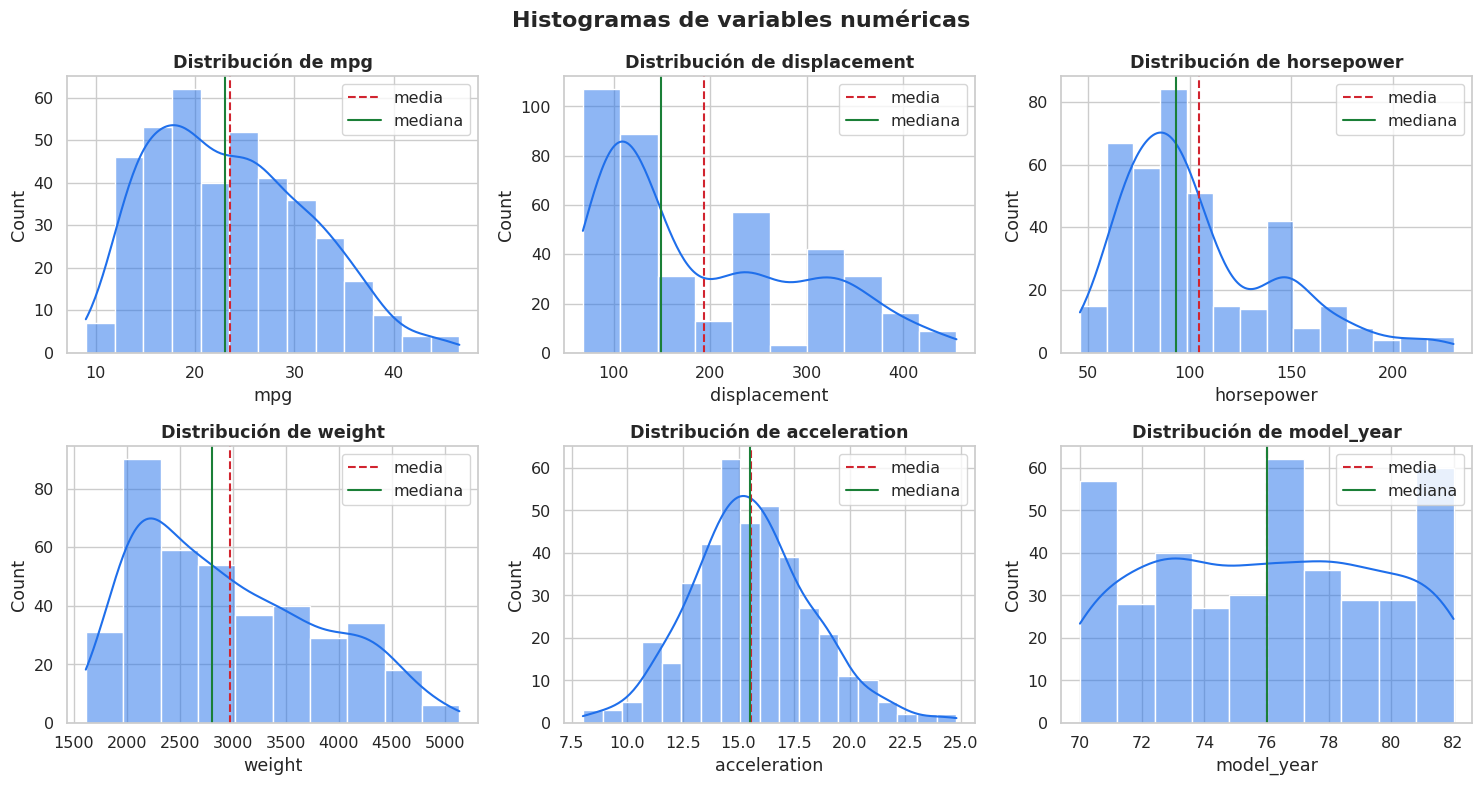

In [ ]:
cont_cols = ["mpg", "displacement", "horsepower", "weight", "acceleration", "model_year"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cont_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="#1f6feb", edgecolor="white")
    ax.axvline(df[col].mean(), color="#d1242f", ls="--", label="media")
    ax.axvline(df[col].median(), color="#1a7f37", ls="-", label="mediana")
    ax.set_title(f"Distribución de {col}")
    ax.legend()
plt.suptitle("Histogramas de variables numéricas", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### 5.2 Gráficos de barras (variables categóricas)

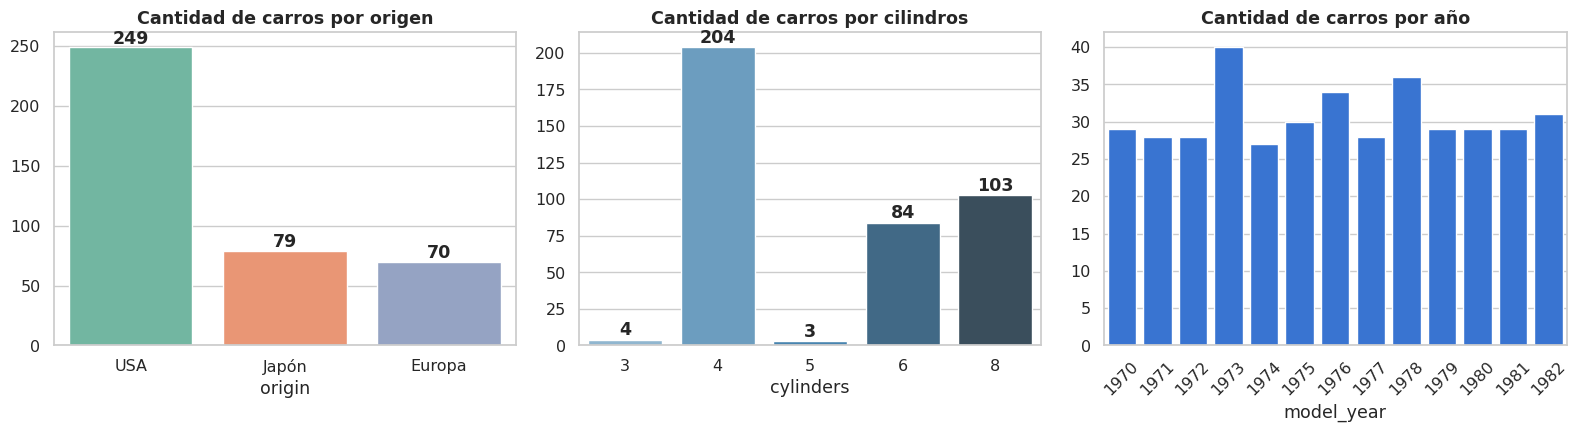

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

orden = df["origin"].map(origen_nombres).value_counts()
sns.barplot(x=orden.index, y=orden.values, ax=axes[0], palette="Set2")
axes[0].set_title("Cantidad de carros por origen")
for i, v in enumerate(orden.values):
    axes[0].text(i, v + 3, str(v), ha="center", fontweight="bold")

cil = df["cylinders"].value_counts().sort_index()
sns.barplot(x=cil.index.astype(str), y=cil.values, ax=axes[1], palette="Blues_d")
axes[1].set_title("Cantidad de carros por cilindros")
for i, v in enumerate(cil.values):
    axes[1].text(i, v + 3, str(v), ha="center", fontweight="bold")

anio = df["model_year"].value_counts().sort_index()
sns.barplot(x=(anio.index + 1900).astype(str), y=anio.values, ax=axes[2], color="#1f6feb")
axes[2].set_title("Cantidad de carros por año")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



### 5.3 Gráficos de dispersión

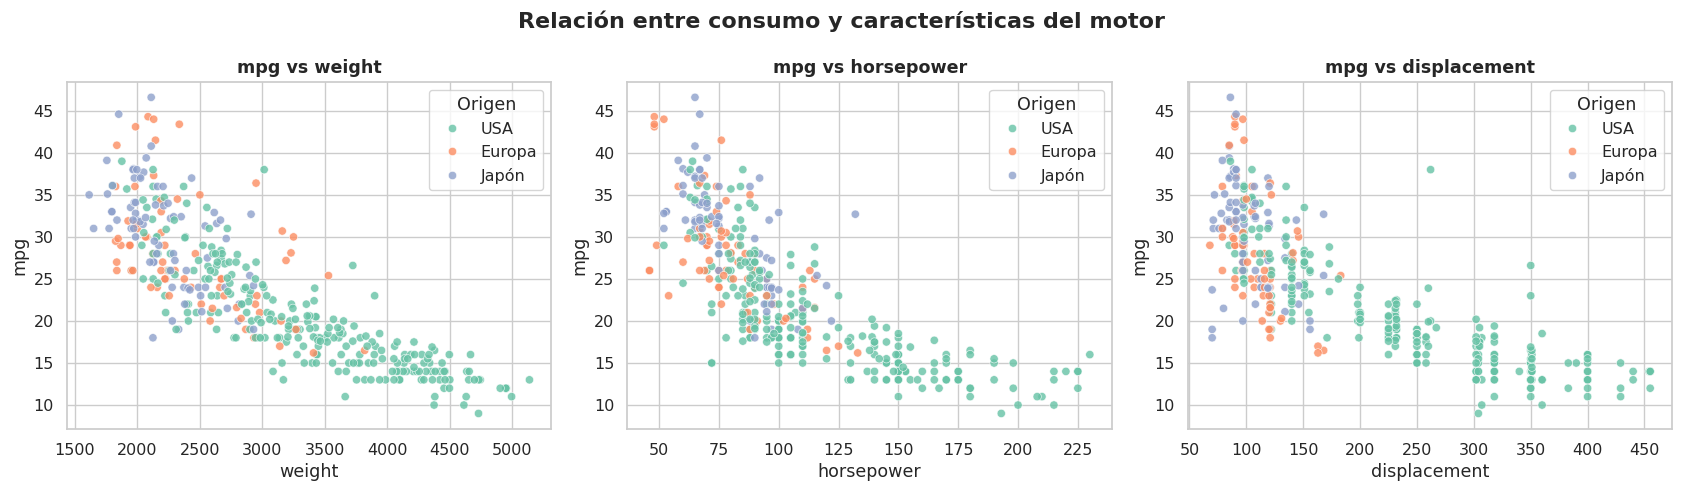

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ["weight", "horsepower", "displacement"]):
    sns.scatterplot(data=df, x=col, y="mpg", hue=df["origin"].map(origen_nombres),
                    hue_order=["USA", "Europa", "Japón"], palette="Set2", alpha=0.8, ax=ax)
    ax.set_title(f"mpg vs {col}")
    ax.legend(title="Origen")
plt.suptitle("Relación entre consumo y características del motor", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Normalización y escalamiento

### 6.1 ¿Qué problema resuelve?

Muchos algoritmos de Machine Learning **comparan distancias o magnitudes** entre variables. Si una variable tiene valores en miles (`weight` ≈ 3000) y otra en decenas (`acceleration` ≈ 15), la primera **domina** los cálculos simplemente por su escala, no porque sea más importante.

**Ejemplo:** distancia entre dos carros

In [ ]:
carro_a = df.loc[0, ["weight", "acceleration"]]
carro_b = df.loc[1, ["weight", "acceleration"]]
print("Carro A:", carro_a.to_dict())
print("Carro B:", carro_b.to_dict())

diff = (carro_a - carro_b) ** 2
print(f"\nContribución de weight a la distancia²:       {diff['weight']:.1f}")
print(f"Contribución de acceleration a la distancia²: {diff['acceleration']:.2f}")
print(f"\n→ weight aporta el {diff['weight']/diff.sum()*100:.2f}% de la distancia total")

Carro A: {'weight': 3504, 'acceleration': 12.0}
Carro B: {'weight': 3693, 'acceleration': 11.5}

Contribución de weight a la distancia²:       35721.0
Contribución de acceleration a la distancia²: 0.25

→ weight aporta el 100.00% de la distancia total


Sin escalar, la aceleración prácticamente **no cuenta** en la distancia.

### 6.2 ¿Qué algoritmos lo necesitan?

| Necesitan escalamiento | No lo necesitan (generalmente) |
|---|---|
| K-Nearest Neighbors (KNN) | Árboles de decisión |
| K-Means | Random Forest |
| SVM | Gradient Boosting (XGBoost, LightGBM) |
| Regresión lineal/logística con regularización | |
| Redes neuronales | |
| PCA | |

### 6.3 Normalización vs Estandarización

En la práctica estos términos se confunden, pero en scikit-learn se distinguen así:

- **Normalización (Min-Max):** lleva los valores a un rango fijo, normalmente **[0, 1]**.
- **Estandarización (Standard / Z-score):** transforma los datos para que tengan **media 0 y desviación estándar 1**.

## 7. Min-Max Scaling y Standard Scaling

### 7.1 Min-Max Scaling

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$


### 7.2 Standard Scaling (Z-score)

$$z = \frac{x - \mu}{\sigma}$$


### 7.3 Fórmulas

In [ ]:
peso = df["weight"]

peso_minmax_manual = (peso - peso.min()) / (peso.max() - peso.min())
peso_std_manual = (peso - peso.mean()) / peso.std(ddof=0)

pd.DataFrame({
    "weight_original": peso,
    "minmax_manual": peso_minmax_manual,
    "standard_manual": peso_std_manual,
}).head(8)

,weight_original,minmax_manual,standard_manual
0,3504,0.536,0.631
1,3693,0.590,0.854
2,3436,0.517,0.550
3,3433,0.516,0.547
4,3449,0.521,0.566
5,4341,0.773,1.620
6,4354,0.777,1.636
7,4312,0.765,1.586


### 7.4 Ahora con scikit-learn

scikit-learn usa siempre la misma "receta" para todos sus transformadores:

1. **`fit()`** → *aprende* los parámetros a partir de los datos (mínimo y máximo, o media y desviación).
2. **`transform()`** → *aplica* la transformación usando esos parámetros.
3. **`fit_transform()`** → hace ambas cosas en un solo paso.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cols_escalar = ["displacement", "horsepower", "weight", "acceleration"]
datos = df[cols_escalar].dropna()   # (temporal) los escaladores no aceptan NaN

minmax = MinMaxScaler()
standard = StandardScaler()

df_minmax = pd.DataFrame(minmax.fit_transform(datos), columns=cols_escalar, index=datos.index)
df_standard = pd.DataFrame(standard.fit_transform(datos), columns=cols_escalar, index=datos.index)

print("Parámetros aprendidos por MinMaxScaler:")
print(pd.DataFrame({"min": minmax.data_min_, "max": minmax.data_max_}, index=cols_escalar))
print("\nParámetros aprendidos por StandardScaler:")
print(pd.DataFrame({"media": standard.mean_, "desv": standard.scale_}, index=cols_escalar))

Parámetros aprendidos por MinMaxScaler:
                  min      max
displacement   68.000  455.000
horsepower     46.000  230.000
weight       1613.000 5140.000
acceleration    8.000   24.800

Parámetros aprendidos por StandardScaler:
                media    desv
displacement  194.412 104.510
horsepower    104.469  38.442
weight       2977.584 848.318
acceleration   15.541   2.755


In [ ]:
# Verificamos que coincide con el cálculo manual
print("¿Min-Max manual == sklearn?  ", np.allclose(peso_minmax_manual.loc[datos.index], df_minmax["weight"]))
# (comparamos sobre las mismas 392 filas sin faltantes que usó sklearn)
w = datos["weight"]
print("¿Standard manual == sklearn? ", np.allclose((w - w.mean()) / w.std(ddof=0), df_standard["weight"]))

¿Min-Max manual == sklearn?   True
¿Standard manual == sklearn?  True



## 8. Comparación antes y después del escalamiento

### 8.1 Comparación numérica

In [ ]:
comparacion = pd.concat({
    "Original": datos.describe().loc[["mean", "std", "min", "max"]],
    "Min-Max": df_minmax.describe().loc[["mean", "std", "min", "max"]],
    "Standard": df_standard.describe().loc[["mean", "std", "min", "max"]],
})
comparacion

displacement  horsepower   weight  acceleration
Original mean       194.412     104.469 2977.584        15.541
         std        104.644      38.491  849.403         2.759
         min         68.000      46.000 1613.000         8.000
         max        455.000     230.000 5140.000        24.800
Min-Max  mean         0.327       0.318    0.387         0.449
         std          0.270       0.209    0.241         0.164
         min          0.000       0.000    0.000         0.000
         max          1.000       1.000    1.000         1.000
Standard mean        -0.000      -0.000   -0.000         0.000
         std          1.001       1.001    1.001         1.001
         min         -1.210      -1.521   -1.609        -2.737
         max          2.493       3.265    2.549         3.360

- **Min-Max:** todas las columnas quedan con min = 0 y max = 1.
- **Standard:** todas quedan con media ≈ 0 y desviación ≈ 1.

### 8.2 Comparación visual: las escalas se igualan

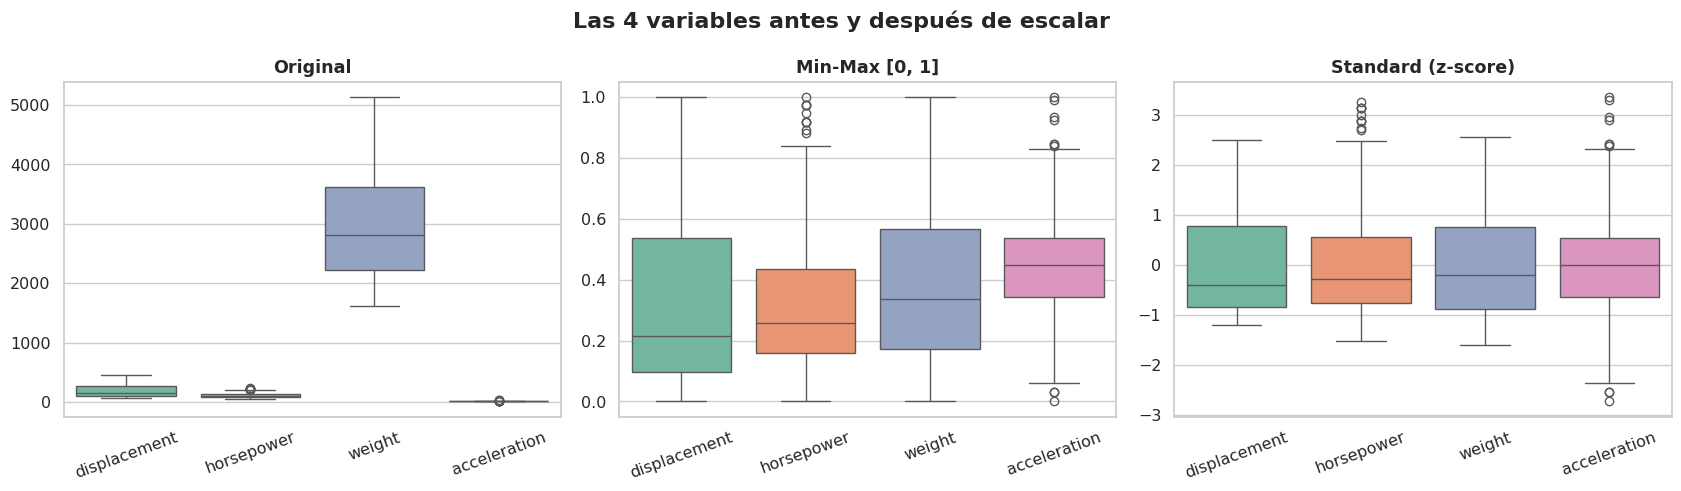

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (titulo, data) in zip(axes, [("Original", datos), ("Min-Max [0, 1]", df_minmax), ("Standard (z-score)", df_standard)]):
    sns.boxplot(data=data, ax=ax, palette="Set2")
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("Las 4 variables antes y después de escalar", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()



### 8.3 La forma de la distribución NO cambia

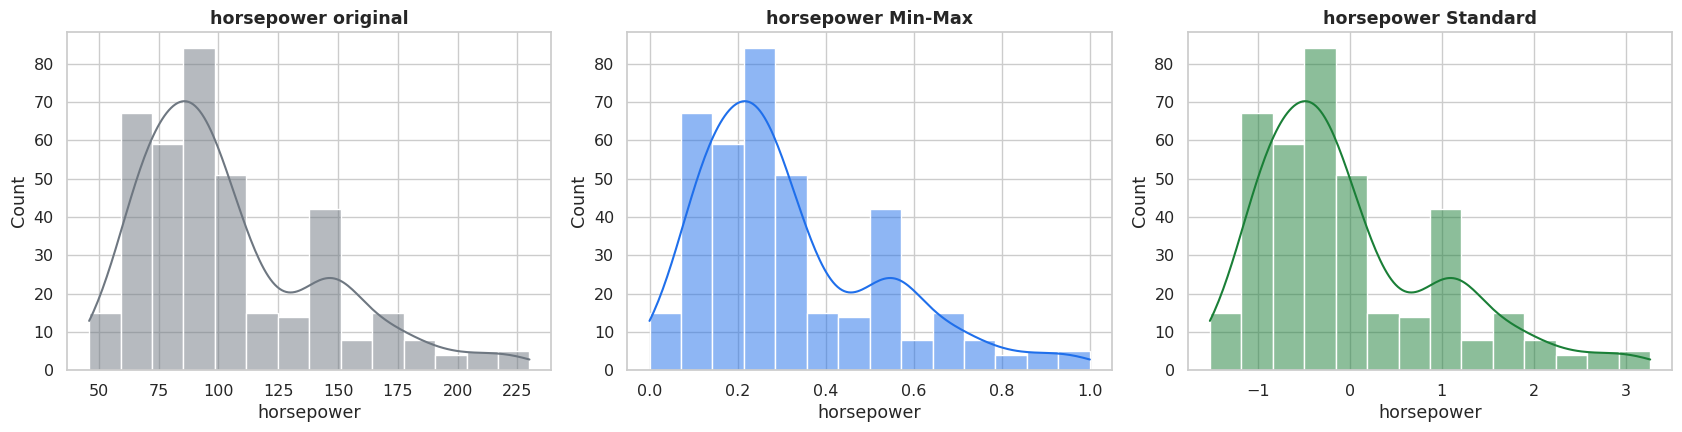

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(datos["horsepower"], kde=True, ax=axes[0], color="#6e7781")
axes[0].set_title("horsepower original")
sns.histplot(df_minmax["horsepower"], kde=True, ax=axes[1], color="#1f6feb")
axes[1].set_title("horsepower Min-Max")
sns.histplot(df_standard["horsepower"], kde=True, ax=axes[2], color="#1a7f37")
axes[2].set_title("horsepower Standard")
plt.tight_layout()
plt.show()



### 8.4 ¿Cuál escoger?

| Situación | Recomendación |
|---|---|
| Se necesita un rango acotado (ej. imágenes, redes neuronales con sigmoide) | **Min-Max** |
| Hay outliers moderados | **Standard** |
| Hay muchos outliers extremos | **RobustScaler** (usa mediana e IQR) |
| Modelos lineales, SVM, PCA, KNN | **Standard** (opción por defecto) |

Para Auto MPG elegiremos **StandardScaler** en el pipeline final, porque `horsepower` y `acceleration` tienen algunos outliers.

<div style="background:#1a7f37; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">PARTE 2 — Variables categóricas y Feature Engineering</h1>
</div>

## 9. Variables numéricas frente a categóricas

### 9.1 Clasificación de variables

```
Variables
├── Numéricas (cuantitativas)
│   ├── Continuas  → pueden tomar cualquier valor en un rango (weight, mpg, acceleration)
│   └── Discretas  → valores enteros contables (cylinders, model_year)
└── Categóricas (cualitativas)
    ├── Nominales  → categorías SIN orden (origin: USA, Europa, Japón; marca)
    └── Ordinales  → categorías CON orden (tamaño: pequeño < mediano < grande)
```

### 9.2 La trampa de `origin`

`origin` está guardada como **número** (1, 2, 3), pero es **categórica nominal**. Si la dejamos así, un modelo lineal entendería que:

- Japón (3) es "el triple" de USA (1).
- Europa (2) está "entre" USA y Japón.


In [ ]:
tipos = pd.DataFrame({
    "dtype_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "tipo_real": ["Numérica continua (objetivo)", "Numérica discreta", "Numérica continua",
                  "Numérica continua", "Numérica continua", "Numérica continua",
                  "Numérica discreta (o temporal)", "Categórica nominal", "Texto (identificador)"],
    "ejemplo": [df[c].iloc[0] for c in df.columns],
})
tipos

,dtype_pandas,valores_unicos,tipo_real,ejemplo
mpg,float64,129,Numérica continua (objetivo),18.000
cylinders,int64,5,Numérica discreta,8
displacement,float64,82,Numérica continua,307.000
horsepower,float64,93,Numérica continua,130.000
weight,int64,351,Numérica continua,3504
acceleration,float64,95,Numérica continua,12.000
model_year,int64,13,Numérica discreta (o temporal),70
origin,int64,3,Categórica nominal,1
car_name,object,305,Texto (identificador),chevrolet chevelle malibu


## 10. Codificación de variables categóricas

Los algoritmos de ML trabajan con **números**. Codificar es convertir categorías en números.

| Técnica | Cómo funciona | Cuándo usarla |
|---|---|---|
| **Mapeo manual / Ordinal** | Cada categoría → un número definido por nosotros | Variables **ordinales** (hay un orden real) |
| **Label Encoding** | Cada categoría → un entero automático | Solo para la variable objetivo en clasificación |
| **One-Hot Encoding** | Una columna binaria (0/1) por cada categoría | Variables **nominales** con pocas categorías |

Primero convertimos `origin` a texto legible para trabajar más cómodamente:

In [ ]:
df["origin_name"] = df["origin"].map({1: "USA", 2: "Europa", 3: "Japón"})
df[["origin", "origin_name"]].drop_duplicates().sort_values("origin")

,origin,origin_name
0,1,USA
19,2,Europa
14,3,Japón


## 11. Mapeo manual y One-Hot Encoding

### 11.1 Mapeo manual (para variables ordinales)

El mapeo manual tiene sentido cuando **las categorías tienen un orden natural**. Por ejemplo, podemos crear una variable de **tamaño del motor** a partir de los cilindros, y mapearla respetando el orden:

In [ ]:
# Primero definimos una categoría ordinal a partir de cylinders
def tamano_motor(cil):
    if cil <= 4:
        return "pequeño"
    elif cil <= 6:
        return "mediano"
    return "grande"

df["engine_size"] = df["cylinders"].apply(tamano_motor)

# Mapeo manual respetando el orden: pequeño < mediano < grande
mapa_tamano = {"pequeño": 0, "mediano": 1, "grande": 2}
df["engine_size_cod"] = df["engine_size"].map(mapa_tamano)

df[["cylinders", "engine_size", "engine_size_cod"]].drop_duplicates().sort_values("cylinders")

,cylinders,engine_size,engine_size_cod
71,3,pequeño,0
14,4,pequeño,0
274,5,mediano,1
15,6,mediano,1
0,8,grande,2




### 11.2 ¿Qué pasa si usamos mapeo manual con una variable nominal?

In [ ]:
# Ejemplo de lo que NO se debe hacer
mal_mapeo = {"USA": 1, "Europa": 2, "Japón": 3}
print("Media de 'origin' codificada como número:", df["origin_name"].map(mal_mapeo).mean().round(2))
print("¿Qué región es 1.6? ¡No tiene sentido! → por eso usamos One-Hot para nominales.")

Media de 'origin' codificada como número: 1.57
¿Qué región es 1.6? ¡No tiene sentido! → por eso usamos One-Hot para nominales.


### 11.3 One-Hot Encoding con pandas (`get_dummies`)

Crea **una columna por categoría**, con 1 si el registro pertenece a esa categoría y 0 si no.

| origin_name | → | origin_USA | origin_Europa | origin_Japón |
|---|---|---|---|---|
| USA | → | 1 | 0 | 0 |
| Europa | → | 0 | 1 | 0 |
| Japón | → | 0 | 0 | 1 |

In [ ]:
dummies = pd.get_dummies(df["origin_name"], prefix="origin", dtype=int)
pd.concat([df[["car_name", "origin_name"]], dummies], axis=1).sample(8, random_state=42)

,car_name,origin_name,origin_Europa,origin_Japón,origin_USA
198,honda civic,Japón,0,1,0
396,ford ranger,USA,0,0,1
33,amc gremlin,USA,0,0,1
208,plymouth volare premier v8,USA,0,0,1
93,plymouth fury gran sedan,USA,0,0,1
84,toyota corolla 1600 (sw),Japón,0,1,0
373,ford fairmont futura,USA,0,0,1
94,chrysler new yorker brougham,USA,0,0,1


#### La "trampa de las variables dummy"

Si sabemos que un carro **no** es de USA ni de Europa, entonces **obligatoriamente** es de Japón. Una de las columnas es redundante (multicolinealidad perfecta), lo cual afecta a modelos lineales. Solución: `drop_first=True` elimina una columna, que pasa a ser la **categoría de referencia**.

In [ ]:
pd.get_dummies(df["origin_name"], prefix="origin", drop_first=True, dtype=int).head()

,origin_Japón,origin_USA
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


### 11.4 One-Hot Encoding con scikit-learn (`OneHotEncoder`)

`get_dummies` es cómodo para explorar, pero en Machine Learning preferimos `OneHotEncoder` porque:

- **Recuerda** las categorías vistas en `fit()` y produce siempre las mismas columnas.
- Con `handle_unknown="ignore"` **no falla** si aparece una categoría nueva en producción.
- Se puede meter dentro de un **Pipeline**.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe.fit(df[["origin_name"]])

print("Categorías aprendidas:", ohe.categories_)
print("Nombres de columnas:  ", ohe.get_feature_names_out())

# ¿Qué pasa con una categoría que nunca vio?
nuevos = pd.DataFrame({"origin_name": ["Japón", "USA", "Corea"]})
pd.DataFrame(ohe.transform(nuevos), columns=ohe.get_feature_names_out(), index=nuevos["origin_name"])

Categorías aprendidas: [array(['Europa', 'Japón', 'USA'], dtype=object)]
Nombres de columnas:   ['origin_name_Europa' 'origin_name_Japón' 'origin_name_USA']


,origin_name_Europa,origin_name_Japón,origin_name_USA
origin_name,,,
Japón,0.000,1.000,0.000
USA,0.000,0.000,1.000
Corea,0.000,0.000,0.000


"Corea" nunca apareció en el entrenamiento: en lugar de generar error, queda como **todo ceros**.

### 11.5 ¿Y para muchas categorías? El caso de la marca

Si aplicamos one-hot a `car_name` crearíamos **~300 columnas**, casi todas con un único 1. Eso se conoce como **alta cardinalidad** y es mala idea. Una mejor estrategia es **extraer información** del texto → eso es *feature engineering*.

In [ ]:
print("Valores únicos en car_name:", df["car_name"].nunique())

Valores únicos en car_name: 305


## 12. Concepto de Feature Engineering

**Feature Engineering** (ingeniería de características) es el proceso de **crear, transformar o seleccionar variables** usando conocimiento del dominio para que el modelo aprenda mejor.

### Tipos de features que podemos crear

| Tipo | Idea | Ejemplo en Auto MPG |
|---|---|---|
| **Relaciones (ratios)** | Dividir o combinar variables | Potencia por peso, cilindrada por cilindro |
| **Indicadores (flags)** | Variable binaria 0/1 de una condición | ¿Es diésel? ¿Es pesado? |
| **Categorías (binning)** | Convertir numérica continua en grupos | Época del modelo, clase de peso |
| **Extracción de texto** | Sacar información de cadenas | Marca a partir de `car_name` |
| **Conversión de unidades** | Adaptar al contexto | mpg → km/L, libras → kg |

Como ingenieros, **conocemos la física del problema**: un carro más pesado necesita más energía para moverse; un motor con más potencia por kilogramo acelera más rápido pero suele consumir más.

## 13. Creación de relaciones, indicadores y categorías

Trabajamos sobre una copia para no alterar `df`.

### 13.1 Relaciones (ratios)

In [ ]:
fe = df.copy()

# 1) Relación potencia/peso: hp por cada 1000 lb (indicador de "deportividad")
fe["power_to_weight"] = fe["horsepower"] / fe["weight"] * 1000

# 2) Cilindrada por cilindro: tamaño de cada cilindro
fe["disp_per_cyl"] = fe["displacement"] / fe["cylinders"]

# 3) Conversión de unidades al sistema métrico (contexto colombiano)
fe["weight_kg"] = fe["weight"] * 0.453592
fe["kpl"] = fe["mpg"] * 0.425144        # km por litro (solo para análisis, es el objetivo)

fe[["car_name", "horsepower", "weight", "power_to_weight", "disp_per_cyl", "weight_kg", "mpg", "kpl"]].head(8)

,car_name,horsepower,weight,power_to_weight,disp_per_cyl,weight_kg,mpg,kpl
0,chevrolet chevelle malibu,130.000,3504,37.100,38.375,1589.386,18.000,7.653
1,buick skylark 320,165.000,3693,44.679,43.750,1675.115,15.000,6.377
2,plymouth satellite,150.000,3436,43.655,39.750,1558.542,18.000,7.653
3,amc rebel sst,150.000,3433,43.694,38.000,1557.181,16.000,6.802
4,ford torino,140.000,3449,40.591,37.750,1564.439,17.000,7.227
5,ford galaxie 500,198.000,4341,45.612,53.625,1969.043,15.000,6.377
6,chevrolet impala,220.000,4354,50.528,56.750,1974.940,14.000,5.952
7,plymouth fury iii,215.000,4312,49.861,55.000,1955.889,14.000,5.952


> `power_to_weight` hereda los **6 faltantes** de `horsepower`. Lo resolveremos dentro del pipeline (imputando *antes* de calcularla).

### 13.2 Extracción de texto: la marca

In [ ]:
fe["brand"] = fe["car_name"].str.split().str[0]
print("Marcas únicas (antes de corregir):", fe["brand"].nunique())
print(sorted(fe["brand"].unique()))

Marcas únicas (antes de corregir): 37
['amc', 'audi', 'bmw', 'buick', 'cadillac', 'capri', 'chevroelt', 'chevrolet', 'chevy', 'chrysler', 'datsun', 'dodge', 'fiat', 'ford', 'hi', 'honda', 'maxda', 'mazda', 'mercedes', 'mercedes-benz', 'mercury', 'nissan', 'oldsmobile', 'opel', 'peugeot', 'plymouth', 'pontiac', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'triumph', 'vokswagen', 'volkswagen', 'volvo', 'vw']


Hay **errores de escritura y abreviaturas** (`chevy`, `chevroelt`, `vw`, `vokswagen`, `toyouta`, `maxda`, `mercedes`…). Esto es limpieza de texto: unificamos con un diccionario de correcciones.

In [ ]:
correcciones = {
    "chevy": "chevrolet", "chevroelt": "chevrolet",
    "vw": "volkswagen", "vokswagen": "volkswagen",
    "toyouta": "toyota", "maxda": "mazda",
    "mercedes": "mercedes-benz",
}
fe["brand"] = fe["brand"].replace(correcciones)
print("Marcas únicas (después de corregir):", fe["brand"].nunique())
fe["brand"].value_counts().head(12)

Marcas únicas (después de corregir): 30


,count
brand,
ford,51
chevrolet,47
plymouth,31
amc,28
dodge,28
toyota,26
datsun,23
volkswagen,22
buick,17


### 13.3 Indicadores (flags binarios)

In [ ]:
# ¿Es diésel? (el nombre lo indica)
fe["is_diesel"] = fe["car_name"].str.contains("diesel").astype(int)

# ¿Es station wagon? (sw = station wagon)
fe["is_wagon"] = fe["car_name"].str.contains(r"\(sw\)|wagon", regex=True).astype(int)

# ¿Es un carro pesado? (por encima de la mediana de peso)
fe["is_heavy"] = (fe["weight"] > fe["weight"].median()).astype(int)

fe[["is_diesel", "is_wagon", "is_heavy"]].sum().rename("cantidad_de_1")

,cantidad_de_1
is_diesel,7
is_wagon,29
is_heavy,199


In [ ]:
fe.loc[fe["is_diesel"] == 1, ["car_name", "mpg", "origin_name"]]

,car_name,mpg,origin_name
244,volkswagen rabbit custom diesel,43.100,Europa
325,vw rabbit c (diesel),44.300,Europa
326,vw dasher (diesel),43.400,Europa
327,audi 5000s (diesel),36.400,Europa
359,peugeot 505s turbo diesel,28.100,Europa
360,volvo diesel,30.700,Europa
387,oldsmobile cutlass ciera (diesel),38.000,USA


Los diésel son pocos (~7) pero tienen **mpg muy alto**: un indicador así puede ayudar a explicar valores que de otro modo parecerían atípicos.

### 13.4 Categorías (binning / discretización)

In [ ]:
# Época del modelo: antes y después de la crisis del petróleo de 1973
fe["era"] = pd.cut(fe["model_year"], bins=[69, 73, 77, 82],
                   labels=["1970-73 (pre-crisis)", "1974-77 (crisis)", "1978-82 (post-crisis)"])

# Clase de peso por cuantiles (cada grupo con ~igual cantidad de carros)
fe["weight_class"] = pd.qcut(fe["weight"], q=3, labels=["liviano", "medio", "pesado"])

fe[["model_year", "era", "weight", "weight_class"]].sample(8, random_state=1)

,model_year,era,weight,weight_class
174,75,1974-77 (crisis),2984,medio
359,81,1978-82 (post-crisis),3230,medio
250,78,1978-82 (post-crisis),3735,pesado
274,78,1978-82 (post-crisis),2830,medio
283,79,1978-82 (post-crisis),3265,medio
232,77,1974-77 (crisis),4335,pesado
117,73,1970-73 (pre-crisis),1867,liviano
348,81,1978-82 (post-crisis),2050,liviano


In [ ]:
print(fe["era"].value_counts().sort_index())
print()
print(fe["weight_class"].value_counts().sort_index())

era
1970-73 (pre-crisis)     125
1974-77 (crisis)         119
1978-82 (post-crisis)    154
Name: count, dtype: int64

weight_class
liviano    134
medio      131
pesado     133
Name: count, dtype: int64


- `pd.cut` → cortes en **valores fijos** que definimos nosotros (conocimiento del dominio).
- `pd.qcut` → cortes por **cuantiles**, para que cada grupo tenga más o menos la misma cantidad de datos.

### 13.5 Una variable derivada del objetivo (¡cuidado!)

In [ ]:
fe["efficiency"] = pd.cut(fe["mpg"], bins=[0, 17, 29, 50], labels=["baja", "media", "alta"])
fe["efficiency"].value_counts()

,count
efficiency,
media,202
baja,99
alta,97


<div style="border-left: 6px solid #d1242f; background: #d1242f14; padding: 12px 16px; border-radius: 6px;">
<b>Fuga de información con features del objetivo</b><br>
<code>efficiency</code> y <code>kpl</code> se calculan a partir de <code>mpg</code>. Sirven para <b>análisis y visualización</b>, pero <b>nunca</b> deben usarse como variables de entrada si queremos predecir <code>mpg</code>: el modelo estaría 'viendo la respuesta'.
</div>

## 14. Visualización de variables creadas

Una variable nueva solo vale la pena si **aporta información**. Veamos si las que creamos se relacionan con el consumo.

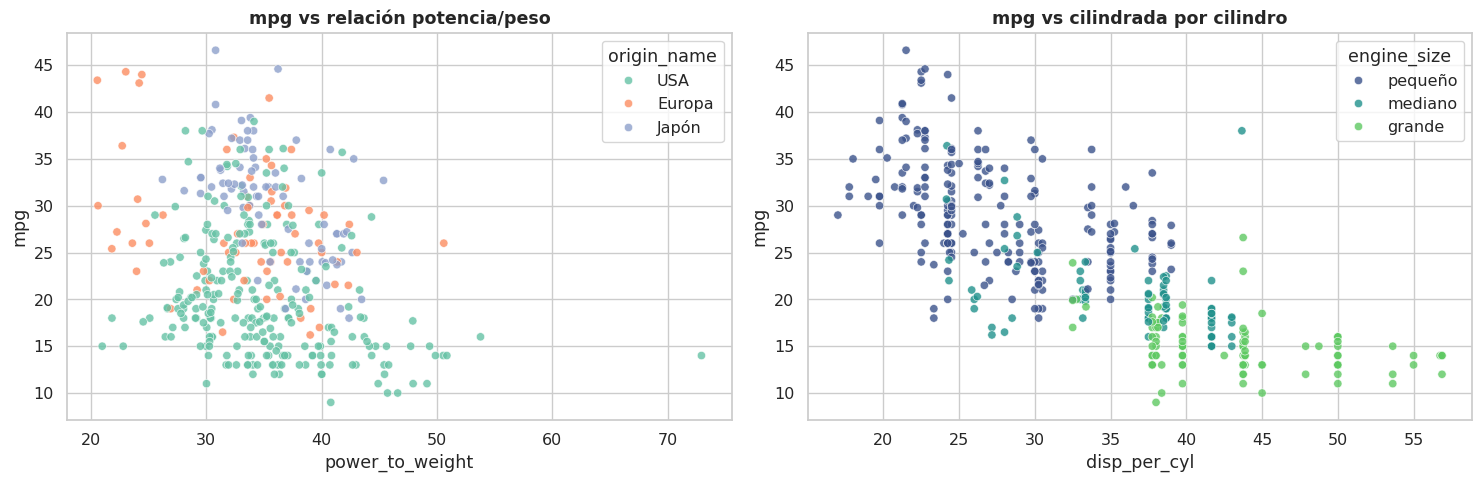

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=fe, x="power_to_weight", y="mpg", hue="origin_name",
                hue_order=["USA", "Europa", "Japón"], palette="Set2", ax=axes[0], alpha=0.8)
axes[0].set_title("mpg vs relación potencia/peso")

sns.scatterplot(data=fe, x="disp_per_cyl", y="mpg", hue="engine_size",
                hue_order=["pequeño", "mediano", "grande"], palette="viridis", ax=axes[1], alpha=0.8)
axes[1].set_title("mpg vs cilindrada por cilindro")
plt.tight_layout()
plt.show()

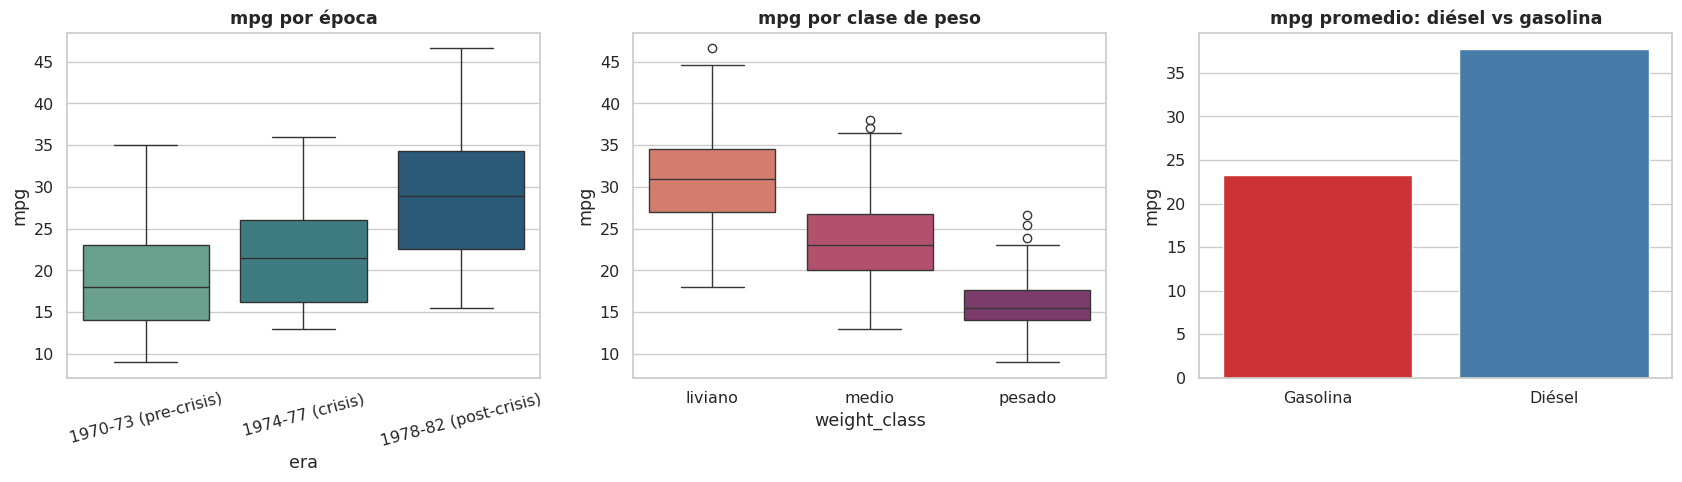

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.boxplot(data=fe, x="era", y="mpg", palette="crest", ax=axes[0])
axes[0].set_title("mpg por época")
axes[0].tick_params(axis="x", rotation=15)

sns.boxplot(data=fe, x="weight_class", y="mpg", palette="flare", ax=axes[1])
axes[1].set_title("mpg por clase de peso")

sns.barplot(data=fe, x="is_diesel", y="mpg", palette="Set1", ax=axes[2], errorbar=None)
axes[2].set_xticks([0, 1], ["Gasolina", "Diésel"])
axes[2].set_title("mpg promedio: diésel vs gasolina")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

**Interpretación:**

- La **época** muestra una mejora clara del rendimiento después de la crisis del petróleo: los fabricantes tuvieron que hacer carros más eficientes.
- La **clase de peso** separa muy bien el consumo: los livianos casi duplican las mpg de los pesados.
- Los **diésel** tienen en promedio un mpg muy superior.

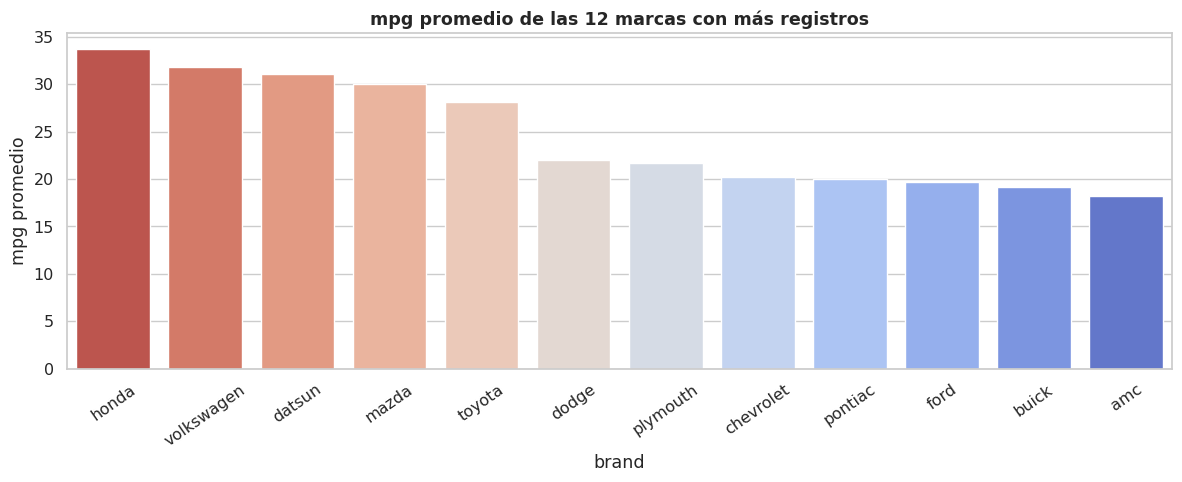

In [ ]:
# Marcas con más carros: rendimiento promedio
top_marcas = fe["brand"].value_counts().head(12).index
orden_marcas = fe[fe["brand"].isin(top_marcas)].groupby("brand")["mpg"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=orden_marcas.index, y=orden_marcas.values, palette="coolwarm_r")
plt.title("mpg promedio de las 12 marcas con más registros")
plt.ylabel("mpg promedio")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

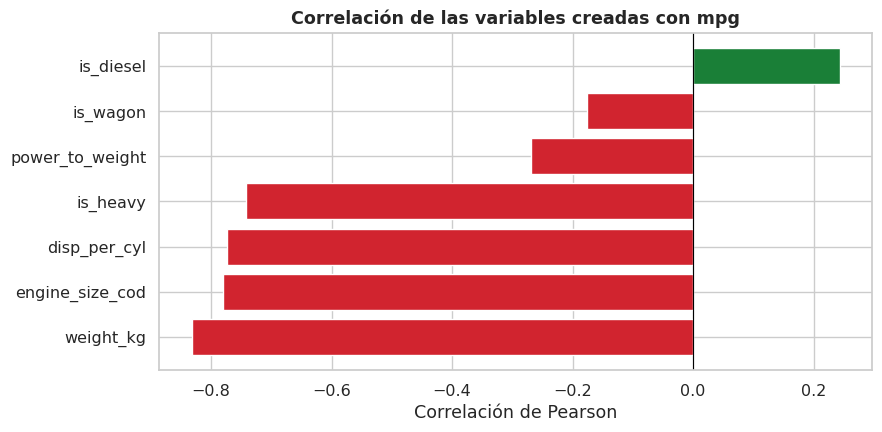

In [ ]:
# ¿Qué tanto se correlacionan las nuevas variables numéricas con mpg?
nuevas = ["power_to_weight", "disp_per_cyl", "weight_kg", "is_diesel", "is_wagon", "is_heavy", "engine_size_cod"]
corr_nuevas = fe[nuevas + ["mpg"]].corr()["mpg"].drop("mpg").sort_values()

plt.figure(figsize=(9, 4.5))
colores = ["#d1242f" if v < 0 else "#1a7f37" for v in corr_nuevas]
plt.barh(corr_nuevas.index, corr_nuevas.values, color=colores)
plt.axvline(0, color="black", lw=0.8)
plt.title("Correlación de las variables creadas con mpg")
plt.xlabel("Correlación de Pearson")
plt.tight_layout()
plt.show()

Las variables creadas tienen **correlaciones significativas** con `mpg`, así que aportan información. Ojo: `weight_kg` es simplemente `weight` en otras unidades (correlación idéntica), por lo que **no añade información nueva** al modelo; solo mejora la interpretación.

**Para pensar:** ¿Qué otra variable se les ocurre crear con estos datos? (Ideas: antigüedad del carro, potencia por cilindro, si la marca es de lujo…)

<div style="background:#8250df; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">PARTE 3 — Pipeline de preprocesamiento con Scikit-learn</h1>
</div>

## 15. Pipeline de preprocesamiento con Scikit-learn

### 15.1 El problema de hacerlo "a mano"

Hasta ahora aplicamos cada paso por separado. En un proyecto real eso causa problemas:

- **Repetición:** hay que aplicar exactamente los mismos pasos al entrenamiento, a la prueba y a los datos nuevos.
- **Errores:** es fácil olvidar un paso o aplicarlo en otro orden.
- **Fuga de información:** si imputamos o escalamos con *todo* el dataset, el test contamina el entrenamiento.

### 15.2 La solución: `Pipeline`

Un **Pipeline** encadena varios pasos en un solo objeto. Funciona como una **línea de producción** en una planta: la materia prima entra por un lado, pasa por cada estación en orden y sale el producto terminado.

```
Datos crudos ──► [Imputar] ──► [Escalar] ──► Datos listos
```

Al llamar `pipeline.fit(X_train)`, cada paso aprende **solo de los datos de entrenamiento**. Luego `pipeline.transform(X_test)` aplica lo aprendido sin volver a aprender.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Un pipeline sencillo: imputar con la mediana y luego estandarizar
pipe_simple = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
])

resultado = pipe_simple.fit_transform(df[["horsepower"]])
print("Faltantes antes:  ", df["horsepower"].isna().sum())
print("Faltantes después:", np.isnan(resultado).sum())
print("Mediana usada para imputar:", pipe_simple.named_steps["imputador"].statistics_[0])
print(f"Media resultante: {resultado.mean():.4f} | Desviación: {resultado.std():.4f}")

Faltantes antes:   6
Faltantes después: 0
Mediana usada para imputar: 93.5
Media resultante: -0.0000 | Desviación: 1.0000


Con **una sola línea** imputamos y escalamos. Además podemos inspeccionar cada paso con `named_steps`.

## 16. ColumnTransformer, imputación, escalamiento y OneHotEncoder

### 16.1 ¿Por qué ColumnTransformer?

Un `Pipeline` aplica los mismos pasos a **todas** las columnas. Pero las numéricas y las categóricas necesitan tratamientos **distintos**:

| Tipo de columna | Imputación | Transformación |
|---|---|---|
| Numéricas | Mediana (robusta a outliers) | `StandardScaler` |
| Categóricas | Moda (valor más frecuente) | `OneHotEncoder` |

El **`ColumnTransformer`** aplica un sub-pipeline diferente a cada grupo de columnas y luego **une los resultados** horizontalmente.

```
                        ┌─ numéricas ──► [Imputar mediana] ─► [Crear feature] ─► [StandardScaler] ─┐
Datos (X) ─► ColumnTransformer                                                                     ├─► Matriz final
                        └─ categóricas ─► [Imputar moda] ─► [OneHotEncoder] ──────────────────────┘
```

### 16.2 Estrategias de imputación disponibles en `SimpleImputer`

| `strategy` | Rellena con | Uso típico |
|---|---|---|
| `"mean"` | Media | Numéricas sin outliers |
| `"median"` | Mediana | Numéricas con outliers o sesgo  |
| `"most_frequent"` | Moda | Categóricas  |
| `"constant"` | Un valor fijo (`fill_value`) | Ej. "desconocido" |

### 16.3 Paso 1: Separar variables de entrada (X) y objetivo (y)

- **Objetivo (y):** `mpg`.
- **Excluimos:** `car_name` (identificador de texto; ya extrajimos de él la marca), y las variables derivadas de `mpg` (fuga de información).
- Para el pipeline usamos el dataset **limpio pero sin transformar**, más la marca extraída.

In [ ]:
datos_modelo = df[["cylinders", "displacement", "horsepower", "weight", "acceleration",
                   "model_year", "origin_name", "mpg"]].copy()
datos_modelo["brand"] = fe["brand"]

X = datos_modelo.drop(columns="mpg")
y = datos_modelo["mpg"]

print("X:", X.shape, "| y:", y.shape)
X.head()

X: (398, 8) | y: (398,)


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_name,brand
0,8,307.000,130.000,3504,12.000,70,USA,chevrolet
1,8,350.000,165.000,3693,11.500,70,USA,buick
2,8,318.000,150.000,3436,11.000,70,USA,plymouth
3,8,304.000,150.000,3433,12.000,70,USA,amc
4,8,302.000,140.000,3449,10.500,70,USA,ford


### 16.4 Paso 2: Dividir en entrenamiento y prueba

Separamos **antes** de cualquier transformación. Así garantizamos que el pipeline aprenda medianas, medias, desviaciones y categorías **solo del entrenamiento**.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {X_train.shape[0]} filas")
print(f"Prueba:        {X_test.shape[0]} filas")
print(f"\nFaltantes de horsepower en train: {X_train['horsepower'].isna().sum()}")
print(f"Faltantes de horsepower en test:  {X_test['horsepower'].isna().sum()}")

Entrenamiento: 318 filas
Prueba:        80 filas

Faltantes de horsepower en train: 5
Faltantes de horsepower en test:  1


### 16.5 Paso 3: Un transformador propio para crear la nueva variable

Queremos que la variable `power_to_weight` se calcule **dentro** del pipeline, y **después** de imputar `horsepower` (si no, heredaría los `NaN`). Para eso usamos `FunctionTransformer`, que convierte cualquier función de Python en un paso de pipeline.

In [ ]:
from sklearn.preprocessing import FunctionTransformer

def agregar_features(X):
    """Recibe un DataFrame numérico ya imputado y agrega variables nuevas."""
    X = X.copy()
    X["power_to_weight"] = X["horsepower"] / X["weight"] * 1000   # hp por cada 1000 lb
    X["disp_per_cyl"] = X["displacement"] / X["cylinders"]         # pulg³ por cilindro
    return X

def nombres_salida(transformer, input_features):
    """Le dice al pipeline cómo se llaman las columnas de salida."""
    return list(input_features) + ["power_to_weight", "disp_per_cyl"]

# Probamos la función por separado
agregar_features(X_train[["cylinders", "displacement", "horsepower", "weight"]].head(3))

,cylinders,displacement,horsepower,weight,power_to_weight,disp_per_cyl
3,8,304.000,150.000,3433,43.694,38.000
18,4,97.000,88.000,2130,41.315,24.250
376,4,91.000,68.000,2025,33.580,22.750


> Como `agregar_features` **añade** columnas, la función `nombres_salida` le indica al pipeline los nombres de las columnas resultantes. Así `get_feature_names_out()` funciona y podremos documentar cada variable al final.

### 16.6 Paso 4: Definir los grupos de columnas

In [ ]:
num_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_features = ["origin_name"]          # categórica nominal → One-Hot
cat_features_brand = ["brand"]          # alta cardinalidad → One-Hot agrupando marcas raras

print("Numéricas:  ", num_features)
print("Categóricas:", cat_features + cat_features_brand)

Numéricas:   ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Categóricas: ['origin_name', 'brand']


### 16.7 Paso 5: Construir los sub-pipelines y el ColumnTransformer

In [ ]:
from sklearn.compose import ColumnTransformer

# --- Sub-pipeline numérico: imputar → crear variables → escalar ---
pipe_numerico = Pipeline(steps=[
    ("imputar", SimpleImputer(strategy="median")),
    ("crear_features", FunctionTransformer(agregar_features, feature_names_out=nombres_salida)),
    ("escalar", StandardScaler()),
])

# --- Sub-pipeline categórico (origen): imputar moda → one-hot ---
pipe_categorico = Pipeline(steps=[
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# --- Sub-pipeline de marca: marcas con menos de 10 carros → "infrequent" ---
pipe_marca = Pipeline(steps=[
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                             sparse_output=False)),
])

# --- ColumnTransformer: une los tres ---
preprocesador = ColumnTransformer(transformers=[
    ("num", pipe_numerico, num_features),
    ("cat", pipe_categorico, cat_features),
    ("marca", pipe_marca, cat_features_brand),
], remainder="drop")

# Pedimos que la salida sea un DataFrame con nombres de columnas
preprocesador.set_output(transform="pandas")
preprocesador

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('crear_features',
                                                  FunctionTransformer(feature_names_out=<function nombres_salida at 0x7b756c8afb00>,
                                                                      func=<function agregar_features at 0x7b756c8afa60>)),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['cylinders', 'displacement', 'horsepower',
                                  'weight', 'acceleration', 'model_...
                                ('cat',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['origin_name']),
                                ('marca',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=10,
                                                                sparse_output=False))]),
                                 ['brand'])])

En Jupyter, el objeto se muestra como un **diagrama interactivo**: se puede hacer clic en cada caja para ver sus parámetros.

**Sobre `min_frequency=10`:** la marca tiene ~30 categorías y muchas con 1–3 carros. En vez de crear una columna por cada una, `OneHotEncoder` agrupa las marcas con menos de 10 apariciones en una sola columna `infrequent_sklearn`. Esto controla la **alta cardinalidad**.

### 16.8 Paso 6: Ajustar con train y transformar

In [ ]:
# fit SOLO con entrenamiento
X_train_t = preprocesador.fit_transform(X_train)

# transform (sin fit) para prueba
X_test_t = preprocesador.transform(X_test)

print(f"Entrenamiento: {X_train.shape} → {X_train_t.shape}")
print(f"Prueba:        {X_test.shape} → {X_test_t.shape}")

Entrenamiento: (318, 8) → (318, 24)
Prueba:        (80, 8) → (80, 24)


## 17. Resultado transformado

### 17.1 Antes vs después (mismas filas)

In [ ]:
print("ANTES (datos originales):")
display(X_train.head())
print("DESPUÉS (datos transformados):")
display(X_train_t.head())

ANTES (datos originales):


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_name,brand
3,8,304.000,150.000,3433,12.000,70,USA,amc
18,4,97.000,88.000,2130,14.500,70,Japón,datsun
376,4,91.000,68.000,2025,18.200,82,Japón,mazda
248,4,91.000,60.000,1800,16.400,78,Japón,honda
177,4,115.000,95.000,2694,15.000,75,Europa,audi


DESPUÉS (datos transformados):


,num__cylinders,num__displacement,num__horsepower,num__weight,num__acceleration,num__model_year,num__power_to_weight,num__disp_per_cyl,cat__origin_name_Europa,cat__origin_name_Japón,cat__origin_name_USA,marca__brand_amc,marca__brand_buick,marca__brand_chevrolet,marca__brand_datsun,marca__brand_dodge,marca__brand_ford,marca__brand_mazda,marca__brand_mercury,marca__brand_plymouth,marca__brand_pontiac,marca__brand_toyota,marca__brand_volkswagen,marca__brand_infrequent_sklearn
3,1.527,1.090,1.266,0.553,-1.319,-1.697,1.516,0.547,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
18,-0.851,-0.923,-0.408,-1.000,-0.413,-1.697,1.120,-1.041,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
376,-0.851,-0.981,-0.948,-1.125,0.928,1.639,-0.167,-1.214,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
248,-0.851,-0.981,-1.164,-1.393,0.275,0.527,-0.208,-1.214,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
177,-0.851,-0.748,-0.219,-0.328,-0.232,-0.307,0.113,-0.521,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000


In [ ]:
print("Columnas generadas por el preprocesador:\n")
for i, nombre in enumerate(preprocesador.get_feature_names_out(), 1):
    print(f"{i:2d}. {nombre}")

Columnas generadas por el preprocesador:

 1. num__cylinders
 2. num__displacement
 3. num__horsepower
 4. num__weight
 5. num__acceleration
 6. num__model_year
 7. num__power_to_weight
 8. num__disp_per_cyl
 9. cat__origin_name_Europa
10. cat__origin_name_Japón
11. cat__origin_name_USA
12. marca__brand_amc
13. marca__brand_buick
14. marca__brand_chevrolet
15. marca__brand_datsun
16. marca__brand_dodge
17. marca__brand_ford
18. marca__brand_mazda
19. marca__brand_mercury
20. marca__brand_plymouth
21. marca__brand_pontiac
22. marca__brand_toyota
23. marca__brand_volkswagen
24. marca__brand_infrequent_sklearn


### 17.2 Verificaciones de calidad

In [ ]:
print("Faltantes en train transformado:", int(X_train_t.isna().sum().sum()))
print("Faltantes en test transformado: ", int(X_test_t.isna().sum().sum()))

cols_num_t = [c for c in X_train_t.columns if c.startswith("num__")]
print("\nColumnas numéricas escaladas (train): media ≈ 0 y desviación ≈ 1")
X_train_t[cols_num_t].agg(["mean", "std"]).T.round(3)

Faltantes en train transformado: 0
Faltantes en test transformado:  0

Columnas numéricas escaladas (train): media ≈ 0 y desviación ≈ 1


,mean,std
num__cylinders,0.000,1.002
num__displacement,-0.000,1.002
num__horsepower,-0.000,1.002
num__weight,0.000,1.002
num__acceleration,-0.000,1.002
num__model_year,-0.000,1.002
num__power_to_weight,0.000,1.002
num__disp_per_cyl,0.000,1.002


In [ ]:
print("Valores aprendidos por los imputadores (solo con train):")
imp_num = preprocesador.named_transformers_["num"].named_steps["imputar"]
print(pd.Series(imp_num.statistics_, index=num_features).rename("mediana_train"))

print("\nCategorías de origen aprendidas:", preprocesador.named_transformers_["cat"].named_steps["onehot"].categories_[0])
print("Marcas poco frecuentes agrupadas:", list(preprocesador.named_transformers_["marca"].named_steps["onehot"].infrequent_categories_[0]))

Valores aprendidos por los imputadores (solo con train):
cylinders         4.000
displacement    148.500
horsepower       92.000
weight         2822.500
acceleration     15.500
model_year       76.000
Name: mediana_train, dtype: float64

Categorías de origen aprendidas: ['Europa' 'Japón' 'USA']
Marcas poco frecuentes agrupadas: ['audi', 'bmw', 'cadillac', 'capri', 'chrysler', 'fiat', 'hi', 'honda', 'mercedes-benz', 'oldsmobile', 'opel', 'peugeot', 'renault', 'saab', 'subaru', 'triumph', 'volvo']


### 17.3 ¿Qué le pasó a los carros que tenían `horsepower` faltante?

In [ ]:
idx_faltantes = X_train[X_train["horsepower"].isna()].index
comparar = pd.concat([
    X_train.loc[idx_faltantes, ["horsepower", "weight"]],
    X_train_t.loc[idx_faltantes, ["num__horsepower", "num__power_to_weight"]],
], axis=1)
comparar.insert(0, "car_name", df.loc[idx_faltantes, "car_name"])
comparar

,car_name,horsepower,weight,num__horsepower,num__power_to_weight
336,ford mustang cobra,NaN,2905,-0.300,-0.485
374,amc concord dl,NaN,3035,-0.300,-0.711
32,ford pinto,NaN,2046,-0.300,1.728
354,renault 18i,NaN,2320,-0.300,0.844
330,renault lecar deluxe,NaN,1835,-0.300,2.588


Los `NaN` quedaron imputados con la **mediana de entrenamiento**, y gracias al orden del pipeline (imputar **antes** de crear features) `power_to_weight` también quedó sin faltantes.

### 17.4 Visualización del resultado

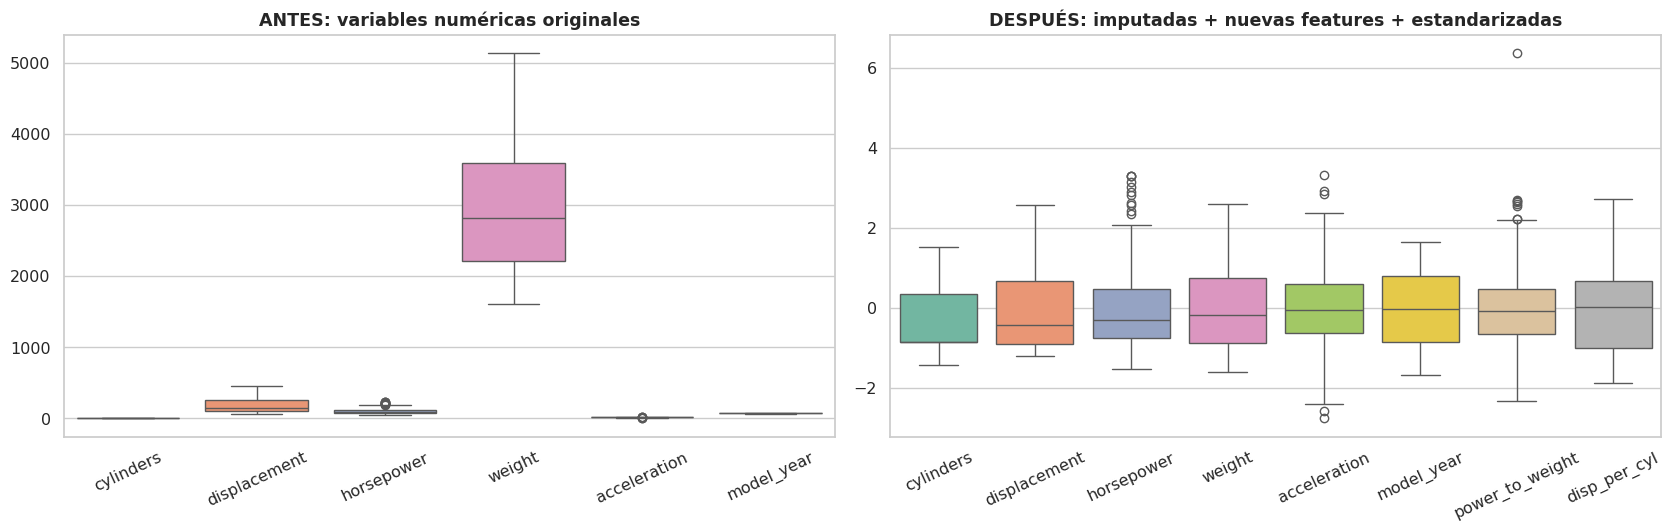

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

sns.boxplot(data=X_train[num_features], ax=axes[0], palette="Set2")
axes[0].set_title("ANTES: variables numéricas originales")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=X_train_t[cols_num_t].rename(columns=lambda c: c.replace("num__", "")),
            ax=axes[1], palette="Set2")
axes[1].set_title("DESPUÉS: imputadas + nuevas features + estandarizadas")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

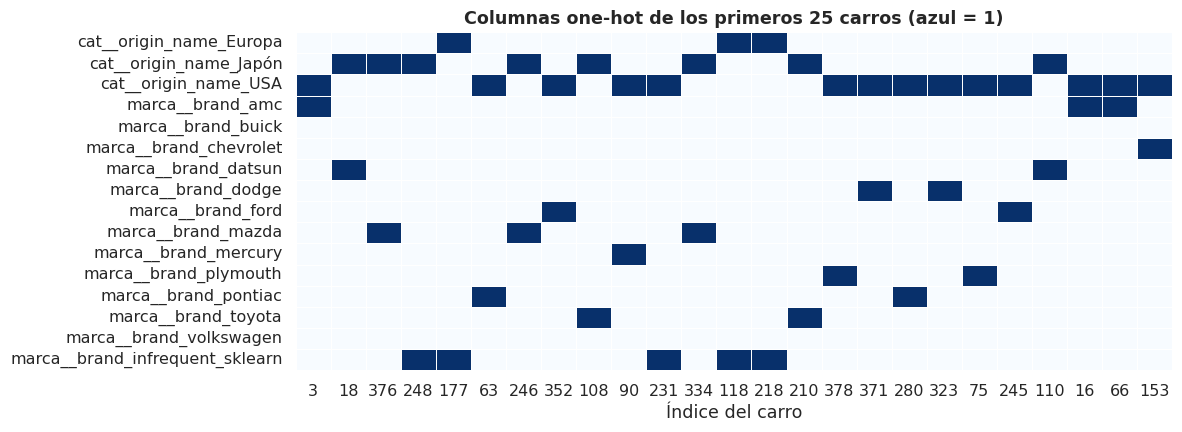

In [ ]:
cols_ohe = [c for c in X_train_t.columns if not c.startswith("num__")]

plt.figure(figsize=(12, 4.5))
sns.heatmap(X_train_t[cols_ohe].head(25).T, cmap="Blues", cbar=False, linewidths=0.4, linecolor="white")
plt.title("Columnas one-hot de los primeros 25 carros (azul = 1)")
plt.xlabel("Índice del carro")
plt.tight_layout()
plt.show()

Cada carro (columna de la imagen) tiene **exactamente un 1** en el bloque de origen y **exactamente un 1** en el bloque de marca.

### 17.5 Bonus: el pipeline completo con un modelo

El verdadero poder del Pipeline aparece al unir preprocesamiento + modelo. Probamos una **regresión lineal** para ver que todo funciona de punta a punta.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, KFold

# Mezclamos los folds porque el CSV está ordenado por año
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

modelo_completo = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", LinearRegression()),
])

modelo_completo.fit(X_train, y_train)
pred = modelo_completo.predict(X_test)

print(f"R² en prueba:  {r2_score(y_test, pred):.3f}")
print(f"MAE en prueba: {mean_absolute_error(y_test, pred):.2f} mpg")

cv = cross_val_score(modelo_completo, X, y, cv=kfold, scoring="r2")
print(f"\nR² validación cruzada (5 folds): {cv.mean():.3f} ± {cv.std():.3f}")

R² en prueba:  0.873
MAE en prueba: 2.04 mpg

R² validación cruzada (5 folds): 0.837 ± 0.021


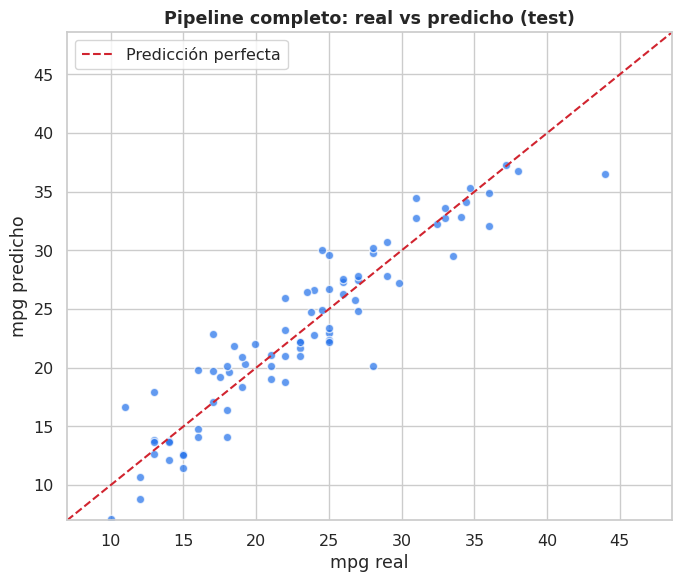

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred, alpha=0.7, color="#1f6feb", edgecolor="white")
lim = [y.min() - 2, y.max() + 2]
plt.plot(lim, lim, "--", color="#d1242f", label="Predicción perfecta")
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("mpg real"); plt.ylabel("mpg predicho")
plt.title("Pipeline completo: real vs predicho (test)")
plt.legend()
plt.tight_layout()
plt.show()

### 17.6 ¿Ayudó el preprocesamiento? Comparación rápida

Comparamos con un modelo que solo usa las numéricas originales (eliminando filas con faltantes y sin escalar ni codificar).

In [ ]:
num_sin_na = datos_modelo.dropna()
cv_basico = cross_val_score(LinearRegression(), num_sin_na[num_features], num_sin_na["mpg"], cv=kfold, scoring="r2")

pd.DataFrame({
    "Modelo": ["Básico (solo numéricas, sin preprocesar)", "Pipeline completo (imputación + FE + escalado + one-hot)"],
    "R² promedio (CV 5)": [cv_basico.mean(), cv.mean()],
}).round(3)

,Modelo,R² promedio (CV 5)
0,"Básico (solo numéricas, sin preprocesar)",0.801
1,Pipeline completo (imputación + FE + escalado ...,0.837


> La mejora viene sobre todo de **la información nueva** (origen, marca, potencia/peso, cilindrada por cilindro). El escalamiento en sí no cambia el R² de una regresión lineal sin regularización, pero es indispensable para modelos como KNN, SVM, redes neuronales o Ridge/Lasso.

### 17.7 Usar el pipeline con un carro nuevo

El pipeline acepta datos **crudos**, incluso con faltantes o categorías desconocidas:

In [ ]:
carros_nuevos = pd.DataFrame({
    "cylinders":    [4, 8, 4],
    "displacement": [98, 350, 120],
    "horsepower":   [70, np.nan, 90],          # un faltante
    "weight":       [2100, 4200, 2500],
    "acceleration": [16.0, 12.0, 15.5],
    "model_year":   [80, 75, 82],
    "origin_name":  ["Japón", "USA", "Europa"],
    "brand":        ["honda", "chevrolet", "skoda"],  # skoda nunca se vio en entrenamiento
})
carros_nuevos["mpg_predicho"] = modelo_completo.predict(carros_nuevos).round(1)
carros_nuevos

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_name,brand,mpg_predicho
0,4,98,70.000,2100,16.000,80,Japón,honda,33.800
1,8,350,NaN,4200,12.000,75,USA,chevrolet,17.400
2,4,120,90.000,2500,15.500,82,Europa,skoda,31.700


## 18. Documentación de variables transformadas

Un buen preprocesamiento **siempre se documenta**. Cualquier persona del equipo (o nosotros en seis meses) debe poder saber de dónde sale cada columna y qué transformación recibió. Construimos un **diccionario de variables** automáticamente a partir del pipeline.

In [ ]:
descripciones = {
    "cylinders": "Número de cilindros del motor",
    "displacement": "Cilindrada del motor (pulg³)",
    "horsepower": "Potencia del motor (hp)",
    "weight": "Peso del vehículo (lb)",
    "acceleration": "Tiempo de 0 a 60 mph (s)",
    "model_year": "Año del modelo (70 = 1970)",
    "power_to_weight": "NUEVA: potencia / peso × 1000 (hp por cada 1000 lb)",
    "disp_per_cyl": "NUEVA: cilindrada / cilindros (pulg³ por cilindro)",
}

filas = []
for col in preprocesador.get_feature_names_out():
    bloque, nombre = col.split("__", 1)
    if bloque == "num":
        origen = nombre if nombre in num_features else "horsepower, weight" if nombre == "power_to_weight" else "displacement, cylinders"
        filas.append([col, origen, "Numérica continua", descripciones[nombre],
                      "Imputación mediana → " + ("creación de variable → " if nombre not in num_features else "") + "StandardScaler",
                      "Valor en desviaciones estándar respecto a la media de train"])
    elif bloque == "cat":
        filas.append([col, "origin", "Binaria (one-hot)", f"1 si el carro es de {nombre.split('_')[-1]}",
                      "origin numérico → texto → imputación moda → OneHotEncoder", "0 = no, 1 = sí"])
    else:
        marca = nombre.replace("brand_", "")
        desc = "1 si la marca tiene < 10 carros en train (agrupada)" if marca == "infrequent_sklearn" else f"1 si la marca es {marca}"
        filas.append([col, "car_name → brand", "Binaria (one-hot)", desc,
                      "Extracción de 1ra palabra → corrección de errores → imputación moda → OneHotEncoder (min_frequency=10)", "0 = no, 1 = sí"])

diccionario = pd.DataFrame(filas, columns=["variable_final", "variable_origen", "tipo", "descripcion", "transformacion", "interpretacion"])
diccionario.index = diccionario.index + 1
diccionario

,variable_final,variable_origen,tipo,descripcion,transformacion,interpretacion
1,num__cylinders,cylinders,Numérica continua,Número de cilindros del motor,Imputación mediana → StandardScaler,Valor en desviaciones estándar respecto a la m...
2,num__displacement,displacement,Numérica continua,Cilindrada del motor (pulg³),Imputación mediana → StandardScaler,Valor en desviaciones estándar respecto a la m...
3,num__horsepower,horsepower,Numérica continua,Potencia del motor (hp),Imputación mediana → StandardScaler,Valor en desviaciones estándar respecto a la m...
4,num__weight,weight,Numérica continua,Peso del vehículo (lb),Imputación mediana → StandardScaler,Valor en desviaciones estándar respecto a la m...
5,num__acceleration,acceleration,Numérica continua,Tiempo de 0 a 60 mph (s),Imputación mediana → StandardScaler,Valor en desviaciones estándar respecto a la m...
6,num__model_year,model_year,Numérica continua,Año del modelo (70 = 1970),Imputación mediana → StandardScaler,Valor en desviaciones estándar respecto a la m...
7,num__power_to_weight,"horsepower, weight",Numérica continua,NUEVA: potencia / peso × 1000 (hp por cada 100...,Imputación mediana → creación de variable → St...,Valor en desviaciones estándar respecto a la m...
8,num__disp_per_cyl,"displacement, cylinders",Numérica continua,NUEVA: cilindrada / cilindros (pulg³ por cilin...,Imputación mediana → creación de variable → St...,Valor en desviaciones estándar respecto a la m...
9,cat__origin_name_Europa,origin,Binaria (one-hot),1 si el carro es de Europa,origin numérico → texto → imputación moda → On...,"0 = no, 1 = sí"
10,cat__origin_name_Japón,origin,Binaria (one-hot),1 si el carro es de Japón,origin numérico → texto → imputación moda → On...,"0 = no, 1 = sí"


In [ ]:
# Variables que NO entraron al modelo y por qué
excluidas = pd.DataFrame([
    ["mpg", "Variable objetivo (y)"],
    ["car_name", "Identificador de texto; se usó para extraer 'brand'"],
    ["origin (numérica)", "Reemplazada por origin_name + One-Hot (es nominal)"],
    ["kpl, efficiency", "Derivadas del objetivo → causarían fuga de información"],
    ["weight_kg", "Redundante con weight (solo cambia la unidad)"],
], columns=["variable", "motivo_exclusion"])
excluidas

,variable,motivo_exclusion
0,mpg,Variable objetivo (y)
1,car_name,Identificador de texto; se usó para extraer 'b...
2,origin (numérica),Reemplazada por origin_name + One-Hot (es nomi...
3,"kpl, efficiency",Derivadas del objetivo → causarían fuga de inf...
4,weight_kg,Redundante con weight (solo cambia la unidad)


In [ ]:
# Guardar la documentación y el dataset transformado (opcional)
diccionario.to_csv("diccionario_variables_transformadas.csv", index_label="n")
X_train_t.to_csv("auto_mpg_train_transformado.csv")
print("Archivos guardados: diccionario_variables_transformadas.csv, auto_mpg_train_transformado.csv")

Archivos guardados: diccionario_variables_transformadas.csv, auto_mpg_train_transformado.csv


### Resumen visual del flujo completo

| Etapa | Qué se hizo | Herramienta |
|---|---|---|
| 1. Diagnóstico | Detectar `?` en horsepower, tipos incorrectos, origin categórica | `info()`, `nunique()`, `isna()` |
| 2. Limpieza mínima | `?` → NaN, renombrar columnas, limpiar texto | `read_csv(na_values="?")` |
| 3. EDA | Estadísticos, histogramas, boxplots, barras, dispersión, correlación | pandas, seaborn |
| 4. Escalamiento | Comparar Min-Max vs Standard | `MinMaxScaler`, `StandardScaler` |
| 5. Codificación | Mapeo manual (ordinal) y One-Hot (nominal) | `map()`, `get_dummies`, `OneHotEncoder` |
| 6. Feature engineering | Ratios, flags, binning, marca | pandas, `FunctionTransformer` |
| 7. Pipeline | Imputar + crear + escalar + codificar en un solo objeto | `Pipeline`, `ColumnTransformer` |
| 8. Documentación | Diccionario de variables finales | `get_feature_names_out()` |

## 19. Conclusiones

1. **El preprocesamiento no es opcional:** Auto MPG parecía limpio, pero tenía faltantes ocultos (`?`), una categórica disfrazada de número (`origin`) y escalas muy diferentes.
2. **El EDA guía las decisiones:** el sesgo y los outliers nos llevaron a imputar con la **mediana** y a escoger **StandardScaler**.
3. **El tipo de variable lo define su significado, no su dtype:** variables nominales → One-Hot; ordinales → mapeo manual.
4. **El feature engineering aporta conocimiento del dominio:** la relación potencia/peso, la marca o la época capturan información que las variables originales no muestran directamente.
5. **Los Pipelines hacen el proceso reproducible y evitan la fuga de información:** todo se aprende solo con entrenamiento y se aplica igual a datos nuevos.
6. **Documentar** cada variable transformada es parte del trabajo profesional.

**Para pensar:** Si este modelo se pusiera en producción en un concesionario, ¿qué pasaría si llega un carro de una marca nueva o sin dato de potencia? (Respuesta: el pipeline ya lo maneja con <code>handle_unknown</code> y <code>SimpleImputer</code>.)

## Referencias

- Quinlan, R. (1993). *Auto MPG* [Dataset]. UCI Machine Learning Repository.
- Documentación de scikit-learn: *Preprocessing data*, *Pipelines and composite estimators*, *ColumnTransformer*.
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly. Capítulo 2.
- Zheng, A. & Casari, A. (2018). *Feature Engineering for Machine Learning*. O'Reilly.

---
<div style="text-align:center; color:#6e7781;">Grupo 3 · Preprocesamiento, Feature Engineering y EDA con Auto MPG</div>